# Tratamento de Imagens de Fundo de Olho para Retinopatia Diabética

Este notebook reúne e reproduz técnicas de tratamento e pré-processamento de imagens de fundo de olho identificadas na literatura recente sobre classificação de retinopatia diabética.

O objetivo é demonstrar visualmente cada transformação aplicada às imagens, explicar sua finalidade e observar seus efeitos antes de qualquer etapa de treinamento de modelos.

## Artigos analisados

### Ghadai et al. (2026)
**A clinically interpretable deep learning pipeline for diabetic retinopathy classification using EfficientNet, advanced data augmentation and GradCAM**

**DOI: 10.1186/s12886-026-04897-4**

Dataset utilizado: APTOS 2019.

Tratamento principal das imagens:
- conversão de RGB para LAB;
- aplicação de CLAHE no canal de luminância L;
- reconstrução da imagem em RGB;
- redimensionamento para 224 × 224 pixels;
- normalização.

In [3]:
# Importa as bibliotecas necessárias;
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [4]:
# Verifica se o diretório principal do projeto existe e retorna o caminho absoluto para ele;
def find_project_root(start_dir=None):
    start_dir = (
        start_dir
        or Path.cwd()
    ).resolve()

    for candidate in [
        start_dir,
        *start_dir.parents
    ]:
        if (
            (candidate / "01.Originais").exists()
            and
            (candidate / "04.Notebooks").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Diretório principal do projeto não encontrado."
    )

BASE_DIR = find_project_root()

APTOS_DIR = (
    BASE_DIR
    / "01.Originais"
    / "DR (Retinopatia Diabética)"
    / "APTOS-2019"
)

print("Projeto:")
print(BASE_DIR)

print("\nAPTOS:")
print(APTOS_DIR)

print("\nExiste:", APTOS_DIR.exists())

Projeto:
C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA

APTOS:
C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA\01.Originais\DR (Retinopatia Diabética)\APTOS-2019

Existe: True


In [5]:
# Mostra os arquivos e diretórios dentro do diretório APTOS;
for caminho in APTOS_DIR.iterdir():
    print(
        "[DIR]" if caminho.is_dir() else "[FILE]",
        caminho.name
    )

[FILE] sample_submission.csv
[FILE] test.csv
[DIR] test_images
[FILE] train.csv
[DIR] train_images


Vamos utilizar o conjunto de treino do APTOS-2019 para demonstração do pré processamento feito no artigo.

In [6]:
# Define os caminhos do conjunto de treino do APTOS;
APTOS_TRAIN_CSV = APTOS_DIR / "train.csv"
APTOS_TRAIN_IMAGES_DIR = APTOS_DIR / "train_images"

# Carrega os rótulos;
aptos_train = pd.read_csv(
    APTOS_TRAIN_CSV
)

print("Registros:", len(aptos_train))

print("\nColunas:")
print(aptos_train.columns.tolist())

print("\nDistribuição das classes:")
print(
    aptos_train["diagnosis"]
    .value_counts()
    .sort_index()
)

aptos_train.head()

Registros: 3662

Colunas:
['id_code', 'diagnosis']

Distribuição das classes:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [7]:
# Seleciona uma imagem da classe 3 (Severe);
exemplo_severe = (
    aptos_train[
        aptos_train["diagnosis"] == 3
    ]
    .iloc[0]
)

id_imagem_exemplo = exemplo_severe["id_code"]

caminho_imagem_exemplo = (
    APTOS_TRAIN_IMAGES_DIR
    / f"{id_imagem_exemplo}.png"
)

print("ID da imagem:", id_imagem_exemplo)
print("Classe:", exemplo_severe["diagnosis"])
print("Existe:", caminho_imagem_exemplo.exists())

ID da imagem: 0104b032c141
Classe: 3
Existe: True


Caminho:
C:\Users\d4rki\Desktop\Pesquisa\OIO+\DATASET_RETINA\01.Originais\DR (Retinopatia Diabética)\APTOS-2019\train_images\0104b032c141.png

Existe: True

Formato da imagem: (1736, 2416, 3)


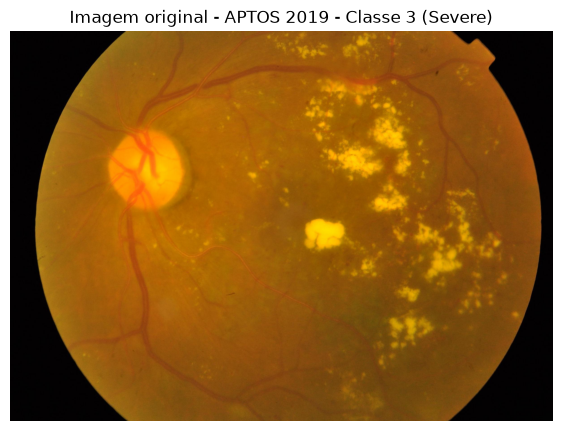

In [8]:
# Lê a imagem de exemplo com PIL;
imagem_pil = Image.open(
    caminho_imagem_exemplo
).convert("RGB")

# Converte para array NumPy;
imagem_rgb = np.array(
    imagem_pil
)

print("Caminho:")
print(caminho_imagem_exemplo)

print(
    "\nExiste:",
    caminho_imagem_exemplo.exists()
)

print(
    "\nFormato da imagem:",
    imagem_rgb.shape
)

plt.figure(figsize=(7, 7))

plt.imshow(imagem_rgb)

plt.title(
    "Imagem original - APTOS 2019 - Classe 3 (Severe)"
)

plt.axis("off")

plt.show()

### Imagem original

A imagem selecionada pertence à classe 3, correspondente à retinopatia diabética grave (*Severe*).

Esta imagem é apresentada inicialmente sem qualquer etapa de pré-processamento, servindo como referência para observar os efeitos das transformações aplicadas posteriormente.

As imagens de fundo de olho podem apresentar diferenças de iluminação, contraste e qualidade de aquisição, fatores que podem dificultar a visualização de estruturas retinais e de características sutis associadas à retinopatia diabética.

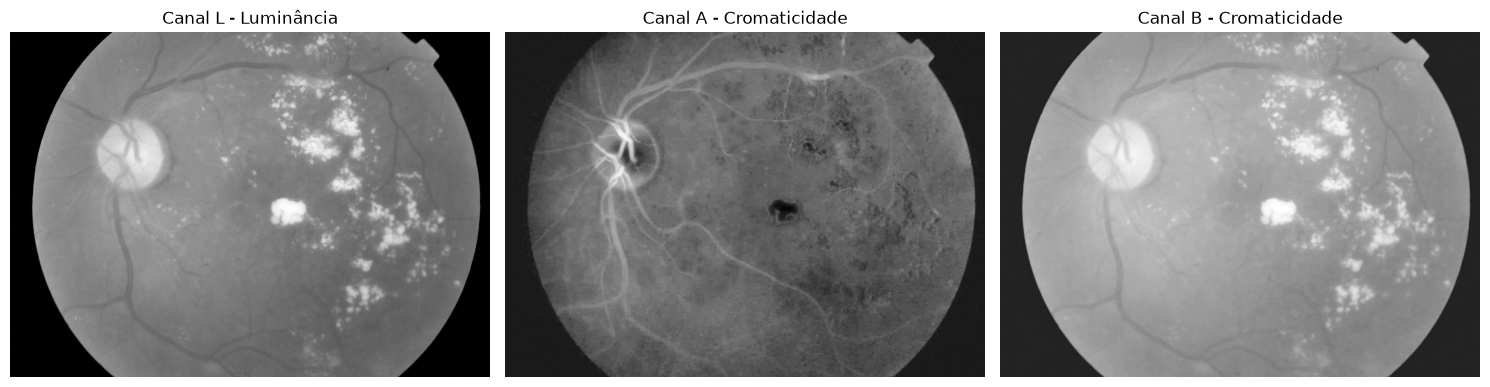

In [9]:
# Converte a imagem RGB para o espaço de cor LAB;
imagem_lab = cv2.cvtColor(
    imagem_rgb,
    cv2.COLOR_RGB2LAB
)

# Separa os canais L, A e B;
canal_l, canal_a, canal_b = cv2.split(
    imagem_lab
)

fig, eixos = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

eixos[0].imshow(
    canal_l,
    cmap="gray"
)
eixos[0].set_title(
    "Canal L - Luminância"
)

eixos[1].imshow(
    canal_a,
    cmap="gray"
)
eixos[1].set_title(
    "Canal A - Cromaticidade"
)

eixos[2].imshow(
    canal_b,
    cmap="gray"
)
eixos[2].set_title(
    "Canal B - Cromaticidade"
)

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()

### Conversão de RGB para LAB

A imagem original em RGB é convertida para o espaço de cor LAB.

Nesse espaço, o canal **L** representa a luminância da imagem, enquanto os canais **A** e **B** armazenam informações relacionadas à cromaticidade (cores).

Essa separação permite modificar principalmente o brilho e o contraste sem aplicar diretamente a mesma transformação sobre as informações de cor da retina.

No método descrito por Ghadai et al. (2026), o CLAHE é aplicado apenas ao canal L, enquanto os canais A e B são preservados.

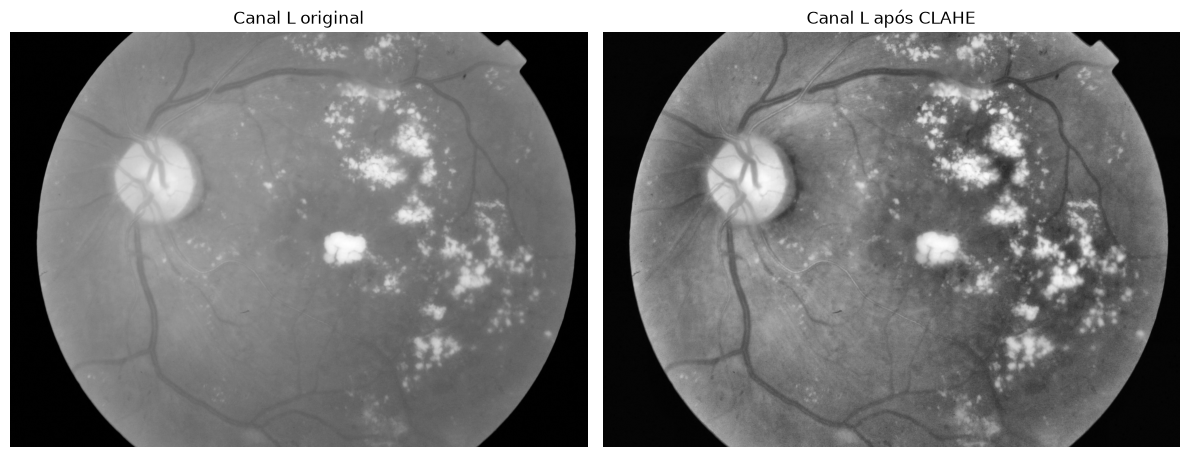

In [10]:
# Cria o objeto CLAHE;
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Aplica CLAHE somente no canal L;
canal_l_clahe = clahe.apply(
    canal_l
)

fig, eixos = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

eixos[0].imshow(
    canal_l,
    cmap="gray"
)
eixos[0].set_title(
    "Canal L original"
)

eixos[1].imshow(
    canal_l_clahe,
    cmap="gray"
)
eixos[1].set_title(
    "Canal L após CLAHE"
)

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()

### Aplicação do CLAHE no canal L

O CLAHE é aplicado somente ao canal de luminância da imagem.

Seu objetivo é melhorar o contraste local, permitindo que regiões com iluminação ou contraste diferentes sejam tratadas de forma mais adequada.

O método divide a imagem em pequenas regiões, realiza equalização local do histograma e limita a amplificação do contraste para evitar o aumento excessivo de ruído.

Neste exemplo, os canais A e B permanecem inalterados. Apenas o canal L é modificado.

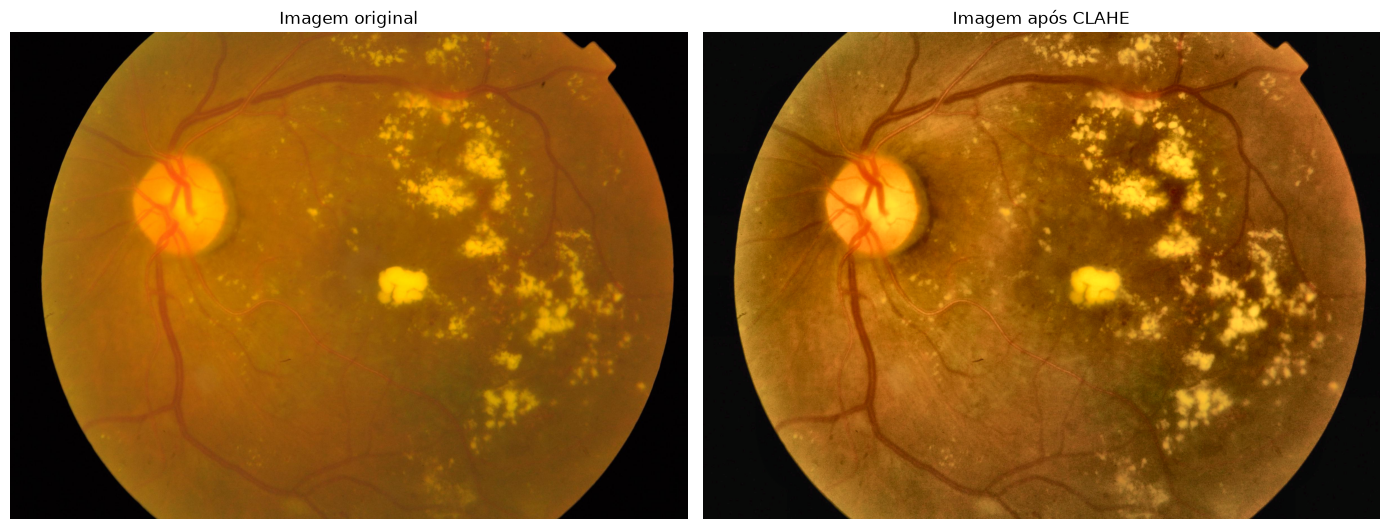

In [11]:
# Junta o canal L tratado com os canais A e B originais;
imagem_lab_clahe = cv2.merge(
    [
        canal_l_clahe,
        canal_a,
        canal_b
    ]
)

# Converte a imagem LAB de volta para RGB;
imagem_rgb_clahe = cv2.cvtColor(
    imagem_lab_clahe,
    cv2.COLOR_LAB2RGB
)

fig, eixos = plt.subplots(
    1,
    2,
    figsize=(14, 7)
)

eixos[0].imshow(
    imagem_rgb
)
eixos[0].set_title(
    "Imagem original"
)

eixos[1].imshow(
    imagem_rgb_clahe
)
eixos[1].set_title(
    "Imagem após CLAHE"
)

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()

### Reconstrução da imagem após CLAHE

Após a aplicação do CLAHE no canal L, o canal de luminância tratado é recombinado com os canais A e B originais.

A imagem resultante é então convertida novamente do espaço LAB para RGB.

Dessa forma, o tratamento é concentrado principalmente sobre a luminância e o contraste da imagem, enquanto as informações de cor são preservadas.

Segundo Ghadai et al. (2026), esse procedimento melhora o contraste local, mantém o ruído sob controle e facilita a visualização de padrões vasculares e características sutis de lesões.

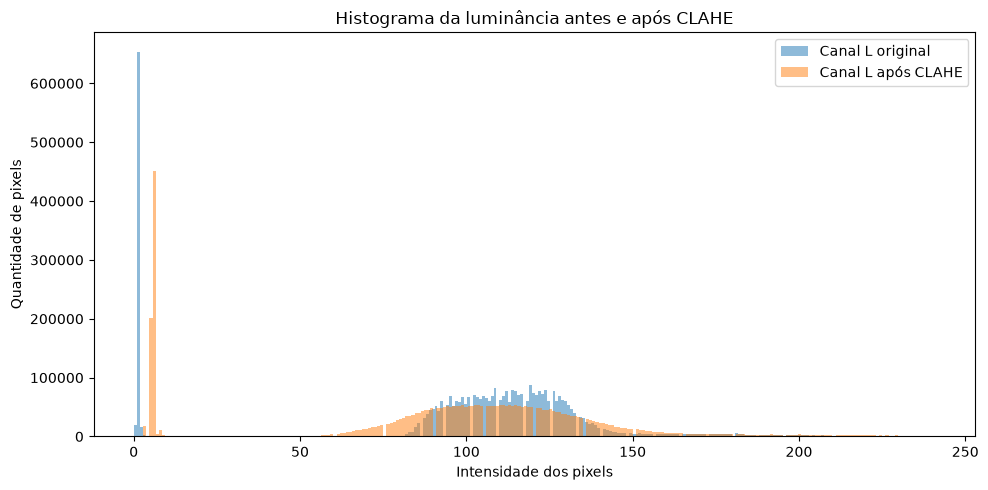

In [12]:
# Compara a distribuição dos valores de luminância
# antes e depois da aplicação do CLAHE;

plt.figure(figsize=(10, 5))

plt.hist(
    canal_l.ravel(),
    bins=256,
    alpha=0.5,
    label="Canal L original"
)

plt.hist(
    canal_l_clahe.ravel(),
    bins=256,
    alpha=0.5,
    label="Canal L após CLAHE"
)

plt.title(
    "Histograma da luminância antes e após CLAHE"
)

plt.xlabel(
    "Intensidade dos pixels"
)

plt.ylabel(
    "Quantidade de pixels"
)

plt.legend()

plt.tight_layout()
plt.show()

### Distribuição da luminância antes e após CLAHE

O histograma mostra como os valores de luminância estão distribuídos na imagem.

O CLAHE modifica essa distribuição localmente para aumentar o contraste entre regiões que anteriormente apresentavam intensidades semelhantes.

Durante esse processo, o método limita a amplificação excessiva do histograma e redistribui os valores que ultrapassam esse limite, ajudando a evitar o aumento exagerado de ruído.

O objetivo não é produzir uma distribuição específica de intensidades, mas melhorar o contraste local da imagem e facilitar a visualização de estruturas retinais.

In [13]:
# Redimensiona mantendo a proporção original
# e adiciona padding até 224 x 224 pixels;

def resize_com_padding(
    imagem,
    tamanho_alvo=(224, 224)
):
    altura, largura = imagem.shape[:2]

    largura_alvo, altura_alvo = tamanho_alvo

    escala = min(
        largura_alvo / largura,
        altura_alvo / altura
    )

    nova_largura = int(
        largura * escala
    )

    nova_altura = int(
        altura * escala
    )

    imagem_redimensionada = cv2.resize(
        imagem,
        (
            nova_largura,
            nova_altura
        )
    )

    padding_horizontal = (
        largura_alvo
        - nova_largura
    )

    padding_vertical = (
        altura_alvo
        - nova_altura
    )

    topo = padding_vertical // 2
    baixo = (
        padding_vertical
        - topo
    )

    esquerda = padding_horizontal // 2
    direita = (
        padding_horizontal
        - esquerda
    )

    imagem_com_padding = cv2.copyMakeBorder(
        imagem_redimensionada,
        topo,
        baixo,
        esquerda,
        direita,
        cv2.BORDER_CONSTANT,
        value=(0, 0, 0)
    )

    return imagem_com_padding

Dimensão original: (1736, 2416, 3)
Dimensão após resize + padding: (224, 224, 3)


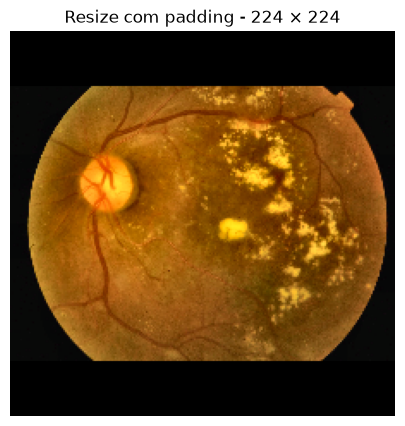

In [14]:
imagem_224_padding = resize_com_padding(
    imagem_rgb_clahe,
    (224, 224)
)

print(
    "Dimensão original:",
    imagem_rgb_clahe.shape
)

print(
    "Dimensão após resize + padding:",
    imagem_224_padding.shape
)

plt.figure(figsize=(5, 5))

plt.imshow(
    imagem_224_padding
)

plt.title(
    "Resize com padding - 224 × 224"
)

plt.axis("off")

plt.show()

### Redimensionamento com padding

Após o pré-processamento com CLAHE, a imagem é redimensionada para se adequar à dimensão de entrada de 224 × 224 pixels.

Entretanto, em vez de realizar um redimensionamento direto para uma imagem quadrada, é mantida a proporção original da fotografia de fundo de olho.

A imagem é redimensionada até que uma de suas dimensões alcance o limite de 224 pixels. O espaço restante é preenchido com padding, utilizando pixels pretos.

Essa abordagem evita distorções geométricas provocadas por um redimensionamento direto, preservando melhor a forma original das estruturas da retina.

O uso de padding nesta implementação foi adotado como decisão metodológica do presente trabalho.

In [17]:
# Demonstração conceitual de normalização;
imagem_normalizada = (
    imagem_224_padding.astype(np.float32)
    / 255.0
)

print("Antes da normalização:")
print("Tipo:", imagem_224_padding.dtype)
print("Mínimo:", imagem_224_padding.min())
print("Máximo:", imagem_224_padding.max())

print("\nApós normalização:")
print("Tipo:", imagem_normalizada.dtype)
print("Mínimo:", imagem_normalizada.min())
print("Máximo:", imagem_normalizada.max())

Antes da normalização:
Tipo: uint8
Mínimo: 0
Máximo: 255

Após normalização:
Tipo: float32
Mínimo: 0.0
Máximo: 1.0


### Normalização

Após o redimensionamento, o estudo informa que as imagens são normalizadas para corresponder aos requisitos de entrada da EfficientNet-B1.

A normalização transforma os valores dos pixels para uma escala mais adequada ao processamento pela rede neural.

Neste notebook, a divisão dos valores por 255 é utilizada apenas como demonstração conceitual, convertendo os pixels originalmente representados entre 0 e 255 para valores entre 0 e 1.

O artigo analisado **não especifica**, na seção metodológica utilizada, os parâmetros exatos empregados na normalização. Portanto, esta etapa não deve ser interpretada como reprodução exata da normalização utilizada pelos autores.

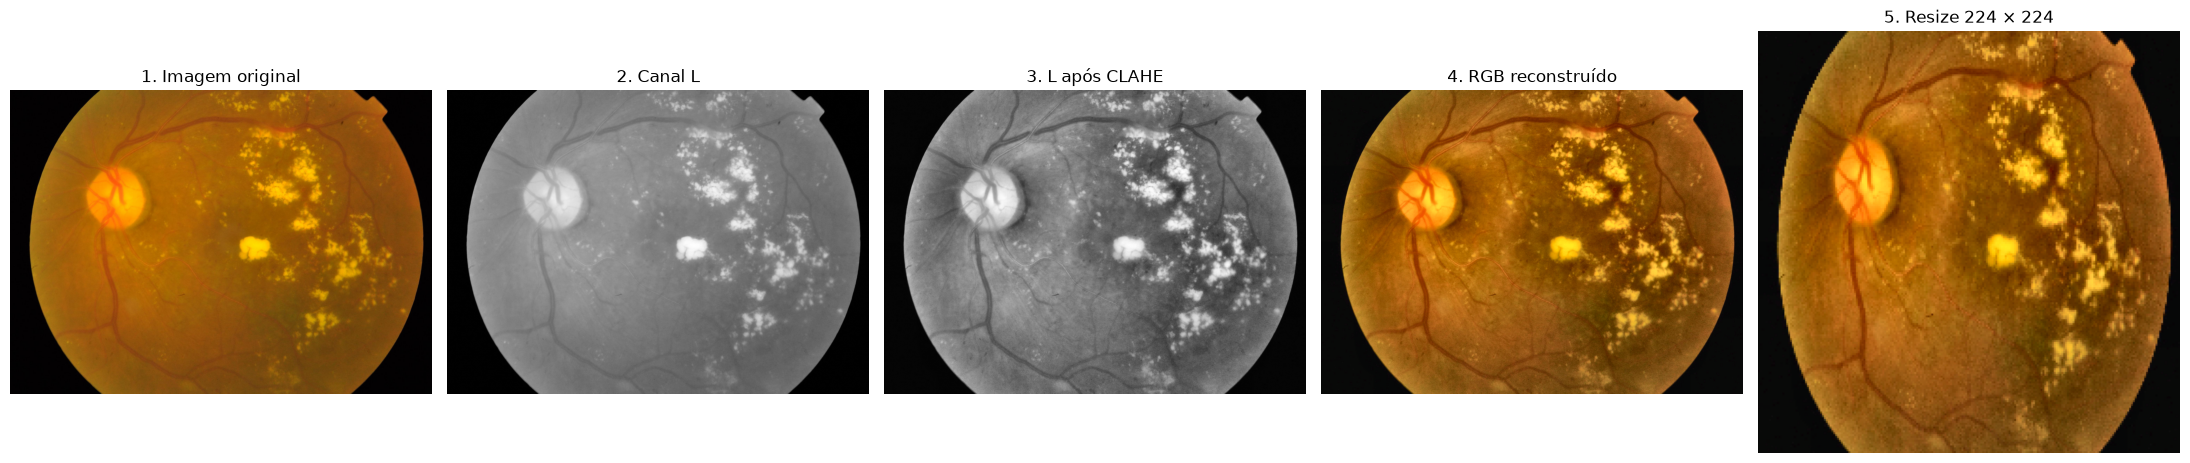

In [ ]:
# Mostra as principais etapas do pré-processamento lado a lado;

fig, eixos = plt.subplots(
    1,
    5,
    figsize=(22, 5)
)

eixos[0].imshow(
    imagem_rgb
)
eixos[0].set_title(
    "1. Imagem original"
)

eixos[1].imshow(
    canal_l,
    cmap="gray"
)
eixos[1].set_title(
    "2. Canal L"
)

eixos[2].imshow(
    canal_l_clahe,
    cmap="gray"
)
eixos[2].set_title(
    "3. L após CLAHE"
)

eixos[3].imshow(
    imagem_rgb_clahe
)
eixos[3].set_title(
    "4. RGB reconstruído"
)

eixos[4].imshow(
    imagem_224_padding
)

eixos[4].set_title(
    "5. Resize + padding\n224 × 224"
)

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()

### Resumo visual do pré-processamento

A sequência acima demonstra as principais etapas do pré-processamento descrito por Ghadai et al. (2026).

1. **Imagem original:** fotografia de fundo de olho antes de qualquer modificação.

2. **Canal L:** após a conversão de RGB para LAB, o canal L representa a luminância da imagem.

3. **Canal L após CLAHE:** o CLAHE é aplicado somente à luminância para melhorar o contraste local, limitando a amplificação excessiva de ruído.

4. **RGB reconstruído:** o canal L tratado é recombinado com os canais A e B originais e convertido novamente para RGB, preservando as informações cromáticas.

5. **Redimensionamento:** a imagem tratada é padronizada para 224 × 224 pixels antes de sua utilização pela EfficientNet-B1.

Após o redimensionamento, o artigo também informa que as imagens são normalizadas para atender aos requisitos de entrada da EfficientNet-B1.